# 03 — Polynomial Regression

> Fitting a curve instead of a straight line, while still using linear regression to do it.

The summary of this lesson is in [README.md](README.md). This notebook is the
full working: the reasoning, the code, and the results.

**Contents**

1. The problem
2. Intuition
3. The mathematics
4. The data
5. Modeling
6. Results and interpretation
7. References

## 1. The problem

Lessons 01 and 02 could only fit straight lines and flat planes. But data does
not have to be straight — a relationship can bend, flatten out, or accelerate.

Looking again at engine size against emissions, the cloud of points may curve
slightly: the gap between a 1-litre and a 2-litre engine need not be the same as
the gap between a 6-litre and a 7-litre one.

This lesson asks whether allowing the model to bend produces a better fit — and
introduces the trick that makes it possible without abandoning linear regression.

## 2. Intuition

Suppose the true relationship curves, but the only tool available is a straight
line. The usual instinct is to reach for a different algorithm.

There is a cheaper trick. Instead of changing the model, **change the features**.
Give the model $x^2$ as an extra column alongside $x$, and a straight-line method
can now produce a curved prediction — because a straight line through
$(x, x^2)$ space is a parabola back in $x$ space.

This is why polynomial regression is still called *linear* regression. "Linear"
refers to the parameters, not to the shape of the curve: the model is a weighted
sum of its features, and it stays a weighted sum no matter how those features
were manufactured. Squaring a column is feature engineering, not a new algorithm.

## 3. The mathematics

**Model.** A degree-2 polynomial in one variable:

$$
\hat{y} = b + \theta_1 x + \theta_2 x^2
$$

Nothing here is new. Writing $x_1 = x$ and $x_2 = x^2$ turns it into

$$
\hat{y} = b + \theta_1 x_1 + \theta_2 x_2
$$

which is exactly the multiple linear regression of lesson 02. The curve comes
from how the features were built, not from how they are combined.

**Building the features.** `PolynomialFeatures(degree=2)` takes each value and
expands it into every power up to the chosen degree:

$$
\begin{bmatrix} v_1 \\ v_2 \\ \vdots \\ v_n \end{bmatrix}
\longrightarrow
\begin{bmatrix}
1 & v_1 & v_1^2 \\
1 & v_2 & v_2^2 \\
\vdots & \vdots & \vdots \\
1 & v_n & v_n^2
\end{bmatrix}
$$

The leading column of ones corresponds to degree 0 and stands in for the
intercept.

**Cost function and fitting.** Both unchanged — residual sum of squares, solved
in closed form by ordinary least squares. The estimator neither knows nor cares
that the third column is the square of the second.

**Degree is a choice.** The degree is not learned from the data; it is set by
hand. A higher degree can always fit the training data at least as well, which is
exactly why training error is a useless guide for choosing it. Section 6 compares
degrees on held-out data instead.

## 4. The data

The same dataset as lessons 01 and 02: fuel consumption ratings and CO2 emissions
for new light duty vehicles sold in Canada in 2014, published as open data by the
Government of Canada.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")

# Fixed seed so the train/test split is identical every run. This matters more
# here than anywhere else so far: the whole lesson is a comparison between
# models, and a comparison means nothing if the data moves between them.
RANDOM_SEED = 42

In [2]:
df = pd.read_csv("data/FuelConsumption.csv")

# take a look at the dataset
df.head()

,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
0,2014,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,2014,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,2014,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,2014,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,2014,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


Selecting the features to work with — the same four numeric columns as lesson 01.

In [3]:
cdf = df[["ENGINESIZE", "CYLINDERS", "FUELCONSUMPTION_COMB", "CO2EMISSIONS"]]
cdf.head(9)

,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_COMB,CO2EMISSIONS
0,2.0,4,8.5,196
1,2.4,4,9.6,221
2,1.5,4,5.9,136
3,3.5,6,11.1,255
4,3.5,6,10.6,244
5,3.5,6,10.0,230
6,3.5,6,10.1,232
7,3.7,6,11.1,255
8,3.7,6,11.6,267


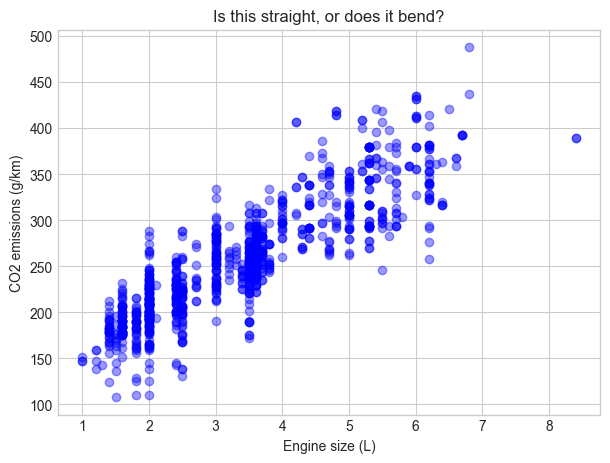

In [4]:
plt.figure(figsize=(7, 5))
plt.scatter(cdf.ENGINESIZE, cdf.CO2EMISSIONS, color="blue", alpha=0.4)
plt.xlabel("Engine size (L)")
plt.ylabel("CO2 emissions (g/km)")
plt.title("Is this straight, or does it bend?")
plt.show()

Honestly, it is hard to tell by eye. There may be a slight flattening at the top
end, but the dominant impression is a straight upward trend with a lot of
vertical spread. That uncertainty is the reason to measure rather than guess.

### Creating train and test datasets

Fit on one portion of the rows, measure on another the model has never seen —
and critically, use the **same** split for every degree compared below.

In [5]:
rng = np.random.default_rng(RANDOM_SEED)
msk = rng.random(len(cdf)) < 0.8

train = cdf[msk]
test = cdf[~msk]

print(f"training rows: {len(train)}")
print(f"test rows:     {len(test)}")

training rows: 859
test rows:     208


## 5. Modeling

### Building polynomial features

Taking engine size as the single input, and expanding it to degree 2.

In [6]:
from sklearn import linear_model
from sklearn.preprocessing import PolynomialFeatures

train_x = train[["ENGINESIZE"]].to_numpy()
train_y = train["CO2EMISSIONS"].to_numpy()

test_x = test[["ENGINESIZE"]].to_numpy()
test_y = test["CO2EMISSIONS"].to_numpy()

poly = PolynomialFeatures(degree=2)
train_x_poly = poly.fit_transform(train_x)
train_x_poly

array([[ 1.  ,  2.  ,  4.  ],
       [ 1.  ,  2.4 ,  5.76],
       [ 1.  ,  3.5 , 12.25],
       ...,
       [ 1.  ,  3.2 , 10.24],
       [ 1.  ,  3.  ,  9.  ],
       [ 1.  ,  3.2 , 10.24]])

One column has become three: $1$, $x$, and $x^2$. A car with a 2.0-litre engine
becomes the row `[1, 2.0, 4.0]`.

Note `fit_transform` on the training data but **`transform`** on the test data
further down. `fit` lets the transformer learn from the data it is given; for
`PolynomialFeatures` that only means recording how many columns to expect, but
the habit matters. Any transformer that learns something numeric — a scaler
learning a mean, an encoder learning categories — must learn it from training
data alone. Calling `fit_transform` on the test set lets test information leak
into the pipeline, and the reported score stops being honest.

In [7]:
reg = linear_model.LinearRegression()
reg.fit(train_x_poly, train_y)

# The coefficients
print("Coefficients: ", reg.coef_)
print("Intercept:    ", reg.intercept_)

Coefficients:  [ 0.         50.49918156 -1.4992115 ]
Intercept:     107.16998009236639


Three coefficients, matching the three columns. The first is 0 because that
column is the constant term, which `LinearRegression` already handles through its
own intercept — so it has nothing left to contribute.

The remaining two are the $x$ and $x^2$ terms. A negative $x^2$ coefficient means
the curve bends downward: emissions rise with engine size, but each extra litre
adds slightly less than the one before.

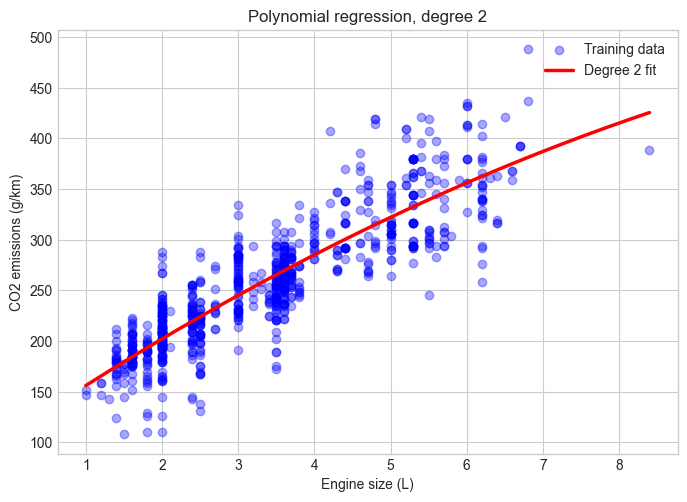

In [8]:
plt.figure(figsize=(8, 5.5))
plt.scatter(
    train.ENGINESIZE, train.CO2EMISSIONS, color="blue", alpha=0.35, label="Training data"
)

# Using an evenly spaced range instead of train_x: train_x is unsorted and has
# gaps, and plotting a curve against unsorted x draws a scribble, not a curve.
XX = np.linspace(train_x.min(), train_x.max(), 200)
yy = reg.intercept_ + reg.coef_[1] * XX + reg.coef_[2] * np.power(XX, 2)

plt.plot(XX, yy, "-r", linewidth=2.5, label="Degree 2 fit")
plt.xlabel("Engine size (L)")
plt.ylabel("CO2 emissions (g/km)")
plt.title("Polynomial regression, degree 2")
plt.legend()

# Saved so README.md can show the result without anyone running this notebook.
plt.savefig("figures/result.png", dpi=150, bbox_inches="tight")
plt.show()

The fitted line is no longer straight — it has a gentle downward bend. Whether
that bend is worth anything is a question for the test set, not for the eye.

## 6. Results and interpretation

### Evaluation

In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# transform, not fit_transform: the expansion was already fitted on the training data.
test_x_poly = poly.transform(test_x)
test_y_ = reg.predict(test_x_poly)

print(f"Mean absolute error:             {mean_absolute_error(test_y, test_y_):.2f} g/km")
print(f"Residual sum of squares (MSE):   {mean_squared_error(test_y, test_y_):.2f}")
print(f"R2-score:                        {r2_score(test_y, test_y_):.4f}")

Mean absolute error:             24.48 g/km
Residual sum of squares (MSE):   981.71
R2-score:                        0.7597


### Does a higher degree help?

Degree is a hand-chosen setting, so the only way to choose it is to try several
and compare on data none of them were fitted to. Every model below uses the same
split, the same feature, and the same estimator — only the degree changes.

In [10]:
results = []

for degree in [1, 2, 3, 4]:
    poly_d = PolynomialFeatures(degree=degree)
    reg_d = linear_model.LinearRegression()
    reg_d.fit(poly_d.fit_transform(train_x), train_y)

    train_pred = reg_d.predict(poly_d.transform(train_x))
    test_pred = reg_d.predict(poly_d.transform(test_x))

    results.append(
        {
            "degree": degree,
            "train R2": r2_score(train_y, train_pred),
            "test R2": r2_score(test_y, test_pred),
            "test MAE": mean_absolute_error(test_y, test_pred),
            "test MSE": mean_squared_error(test_y, test_pred),
        }
    )

pd.DataFrame(results).set_index("degree").round(4)

,train R2,test R2,test MAE,test MSE
degree,,,,
1,0.7657,0.7568,24.4294,993.5021
2,0.7681,0.7597,24.4773,981.7135
3,0.7687,0.7621,24.2559,971.7057
4,0.7688,0.7623,24.2173,971.1388


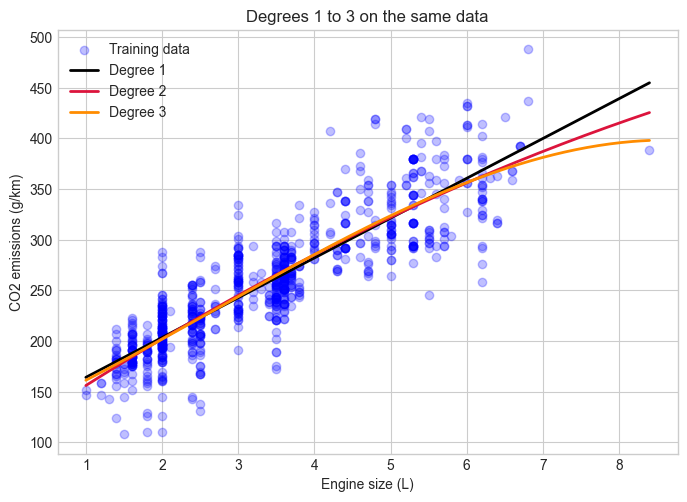

In [11]:
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(train.ENGINESIZE, train.CO2EMISSIONS, color="blue", alpha=0.25, label="Training data")

XX_grid = np.linspace(train_x.min(), train_x.max(), 200).reshape(-1, 1)

for degree, colour in zip([1, 2, 3], ["black", "crimson", "darkorange"]):
    poly_d = PolynomialFeatures(degree=degree)
    reg_d = linear_model.LinearRegression()
    reg_d.fit(poly_d.fit_transform(train_x), train_y)
    ax.plot(
        XX_grid,
        reg_d.predict(poly_d.transform(XX_grid)),
        color=colour,
        linewidth=2,
        label=f"Degree {degree}",
    )

ax.set_xlabel("Engine size (L)")
ax.set_ylabel("CO2 emissions (g/km)")
ax.set_title("Degrees 1 to 3 on the same data")
ax.legend()
plt.show()

### Reading the result

The three curves sit almost on top of one another, and the test scores say the
same thing: moving from a straight line to a quadratic changes R² by a few
thousandths, and a cubic adds a few thousandths more. Against a typical error of
roughly 24 g/km, none of that is a meaningful improvement.

**The honest conclusion is that this relationship is essentially straight.**
Polynomial features gave the model permission to bend, and it barely used that
permission. That is a real result, not a failed experiment — the method was
applied correctly and the data said no.

Two things are worth noticing in the comparison table:

- **Training R² never decreases as degree rises.** It cannot: a higher-degree
  model contains every lower-degree model as a special case, so it can always
  match one by setting the extra coefficients to zero. This is precisely why
  degree must never be chosen on training scores.
- **Test R² is what tells the truth**, and it flattens out almost immediately.
  Pushed far enough, a high-degree polynomial starts chasing individual points
  and test R² falls while training R² keeps climbing — the textbook picture of
  overfitting.

What the earlier lessons showed still holds: the vertical spread at each engine
size is caused by properties of the car this model cannot see, and no amount of
curvature in a single feature can explain it. Lesson 02 raised R² from 0.76 to
0.84 by adding real information. Bending the line adds none.

## 7. References

- Course: Machine Learning with Python (Jadi) — lesson on polynomial regression,
  which uses this dataset and framing.
- Dataset: [Fuel consumption ratings, Government of Canada open data](https://open.canada.ca/data/en/dataset/98f1a129-f628-4ce4-b24d-6f16bf24dd64)
- scikit-learn documentation: [Polynomial regression: extending linear models with basis functions](https://scikit-learn.org/stable/modules/linear_model.html#polynomial-regression-extending-linear-models-with-basis-functions)